# Personas de 65 años o más en riesgo de pobreza

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "riesgo-pobreza-mayores"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Personas de 65 años o más en riesgo de pobreza"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de la población de 65 años o más"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El porcentaje de las personas de 65 años o más que viven en hogares con una renta disponible por unidad de consumo (ajustada por el tamaño del hogar) inferior al 60 % de la mediana de su país: la *tasa de riesgo de pobreza*, el indicador de pobreza relativa de la UE.

**Cómo se lee.** Un valor de 17 significa que 17 de cada 100 personas mayores viven en hogares con una renta por debajo de ese umbral. Como el umbral depende de la renta mediana de todo el país, la tasa de los mayores puede subir si las pensiones se mantienen mientras crecen los salarios, y bajar en una crisis que reduce las rentas del trabajo aunque las pensiones no cambien.

**Limitaciones.**
- **Pobreza relativa**, no carencia material: no compara niveles de vida entre países.
- La renta no incluye el valor de la vivienda en propiedad (ni el alquiler que se ahorra quien la tiene), muy extendida entre las personas mayores en España.
- **Rupturas en España:** de 1995 a 2001 las tasas salen del Panel de Hogares de la Unión Europea (PHOGUE) y en 2002 de otra fuente, redondeadas a números enteros, y desde 2004 de la encuesta de condiciones de vida (EU-SILC); Eurostat marca rupturas de serie en 2002 y 2004, y no hay dato de 2003. En EU-SILC los ingresos son los del año anterior al de la encuesta.
- **EE. UU. y Canadá** salen de otra fuente, la base de distribución de la renta de la OCDE (IDD), con el mismo umbral pero otra encuesta en cada país y otra escala para ajustar la renta al tamaño del hogar. La sección 3 compara España en las dos fuentes. La IDD no publica una media de la OCDE.

## 2. Descarga

- **España y UE-27:** Eurostat, tasa de riesgo de pobreza por umbral, edad y sexo (`ilc_li02`), 65 años o más (`Y_GE65`), ambos sexos, umbral del 60 % de la mediana (`B_60`, `MED_EI`).
- **EE. UU. y Canadá:** OCDE, base de distribución de la renta (IDD, `OECD.WISE.INE,DSD_WISE_IDD@DF_IDD,1.0`), tasa de pobreza con la renta disponible (`PR_INC_DISP`), más de 65 años (`Y_GT65`), umbral del 60 % de la mediana (`PL_60`), definición de renta vigente (`METH2012`, `D_CUR`). También España, para compararla con Eurostat.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, oecd
from lib.tipos import FuenteMeta

FILTROS = {"freq": "A", "age": "Y_GE65", "sex": "T", "unit": "PC", "rskpovth": "B_60", "statinfo": "MED_EI"}
eu, fuentes_eu = eurostat.get("ilc_li02", FILTROS, desde=DESDE)

# IDD: REF_AREA.FREQ.MEASURE.STATISTICAL_OPERATION.UNIT_MEASURE.AGE.METHODOLOGY.DEFINITION.POVERTY_LINE
DATAFLOW_IDD = "OECD.WISE.INE,DSD_WISE_IDD@DF_IDD,1.0"
CLAVE_IDD = "{AREA}.A.PR_INC_DISP._Z.PT_POP.Y_GT65.METH2012.D_CUR.PL_60"
idd, fuentes_idd = oecd.get(
    DATAFLOW_IDD, CLAVE_IDD, areas={"USA": "eeuu", "CAN": "canada", "ESP": "espana_idd", "OECD": "ocde"}, desde=DESDE
)
print(idd.groupby("serie")["periodo"].agg(["min", "max", "count"]))

             min   max  count
serie                        
canada      1976  2023     48
eeuu        2013  2023     11
espana_idd  2007  2023     17


## 3. Transformación

Sin transformación: las dos fuentes publican el porcentaje. España y la UE-27 salen de Eurostat; EE. UU. y Canadá, de la IDD. La serie de la OCDE queda en `null` (la IDD no publica su media).

In [ ]:
assert "ocde" not in set(idd["serie"]), "la IDD publica ya la media de la OCDE: usarla"
df = pd.concat([eu, idd[idd["serie"].isin(["eeuu", "canada"])]], ignore_index=True)
HOY = fuentes_eu[0].fecha_consulta
fuentes = [
    FuenteMeta(f.serie, f.organismo, "ilc_li02 (age=Y_GE65, sex=T, rskpovth=B_60, statinfo=MED_EI, unit=PC)", f.url, f.fecha_consulta)
    for f in fuentes_eu
] + [
    FuenteMeta(f.serie, f.organismo, "DSD_WISE_IDD@DF_IDD (PR_INC_DISP, Y_GT65, METH2012, D_CUR, PL_60)", f.url, f.fecha_consulta)
    for f in fuentes_idd if f.serie in ("eeuu", "canada")
] + [FuenteMeta("ocde", oecd.ORGANISMO, "DSD_WISE_IDD@DF_IDD: sin media de la OCDE", oecd.URL_EXPLORER, HOY)]
df = pd.concat([df, pd.DataFrame({"serie": ["ocde"], "periodo": [DESDE], "valor": [float("nan")]})], ignore_index=True)
assert df["valor"].dropna().between(0, 70).all(), "valor fuera de rango: ¿unidades?"

serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"]
es_eu, es_idd = serie(eu, "espana"), serie(idd, "espana_idd")
comp = pd.DataFrame({"Eurostat (año de la encuesta)": es_eu, "IDD": es_idd})
comp["IDD − Eurostat"] = comp["IDD"] - comp["Eurostat (año de la encuesta)"]
display(comp.dropna().round(1))
dif = comp["IDD − Eurostat"].dropna()
COMUN = (int(dif.index.min()), int(dif.index.max()))
DIF_MIN, DIF_MAX = dif.min(), dif.max()
ANIOS_ES = sorted(es_eu.index)
FALTA_ES = sorted(set(range(ANIOS_ES[0], ANIOS_ES[-1] + 1)) - set(ANIOS_ES))

,Eurostat (año de la encuesta),IDD,IDD − Eurostat
periodo,,,
2007,26.1,32.2,6.1
2008,25.5,26.6,1.1
2009,23.8,25.6,1.8
2010,21.8,23.9,2.1
2011,19.8,21.0,1.2
2012,14.8,17.8,3.0
2013,12.7,15.2,2.5
2014,11.4,15.0,3.6
2015,12.3,17.2,4.9


### Notas

In [ ]:
def fmt(x, decimales=1):
    return estilos.formato_es(x, decimales).replace("-", "−")


def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


NOTAS = [
    "España y UE-27: Eurostat (ilc_li02), porcentaje de las personas de 65 años o más con una renta disponible "
    "equivalente inferior al 60 % de la mediana nacional. Media UE-27 de composición actual (EU27_2020).",
    f"Rupturas de serie en España en 2002 y 2004, según Eurostat: de {ANIOS_ES[0]} a 2001 las tasas salen del Panel "
    f"de Hogares de la Unión Europea (PHOGUE) y en 2002 de otra fuente, redondeadas a números enteros, y desde 2004 de "
    f"la encuesta de condiciones de vida (EU-SILC), cuyos ingresos son los del año anterior al de la encuesta; sin "
    f"dato en {unir(FALTA_ES)}.",
    "EE. UU. y Canadá: OCDE, base de distribución de la renta (IDD), tasa de pobreza de la población de más de 65 años "
    "con el umbral del 60 % de la mediana de la renta disponible (definición de renta vigente desde 2012); otra "
    "encuesta en cada país y otra escala de equivalencia (la raíz cuadrada del tamaño del hogar, en lugar de la escala "
    "de la OCDE modificada de Eurostat).",
    f"España en las dos fuentes: de {COMUN[0]} a {COMUN[1]}, la tasa de la IDD "
    + (f"es entre {fmt(DIF_MIN)} y {fmt(DIF_MAX)} puntos más alta que la de Eurostat" if DIF_MIN > 0 else
       f"difiere de la de Eurostat entre {fmt(DIF_MIN)} y {fmt(DIF_MAX)} puntos")
    + ", por lo que la comparación con EE. UU. y Canadá es solo orientativa.",
    "OCDE: sin dato. La IDD no publica la media de la OCDE.",
    "La renta no incluye el valor de la vivienda en propiedad, que tienen muchas personas mayores.",
]
for n in NOTAS:
    print("-", n)

- España y UE-27: Eurostat (ilc_li02), porcentaje de las personas de 65 años o más con una renta disponible equivalente inferior al 60 % de la mediana nacional. Media UE-27 de composición actual (EU27_2020).
- Rupturas de serie en España en 2002 y 2004, según Eurostat: de 1995 a 2001 las tasas salen del Panel de Hogares de la Unión Europea (PHOGUE) y en 2002 de otra fuente, redondeadas a números enteros, y desde 2004 de la encuesta de condiciones de vida (EU-SILC), cuyos ingresos son los del año anterior al de la encuesta; sin dato en 2003.
- EE. UU. y Canadá: OCDE, base de distribución de la renta (IDD), tasa de pobreza de la población de más de 65 años con el umbral del 60 % de la mediana de la renta disponible (definición de renta vigente desde 2012); otra encuesta en cada país y otra escala de equivalencia (la raíz cuadrada del tamaño del hogar, en lugar de la escala de la OCDE modificada de Eurostat).
- España en las dos fuentes: de 2007 a 2023, la tasa de la IDD es entre 1,1 y 7,

## 4. Visualización

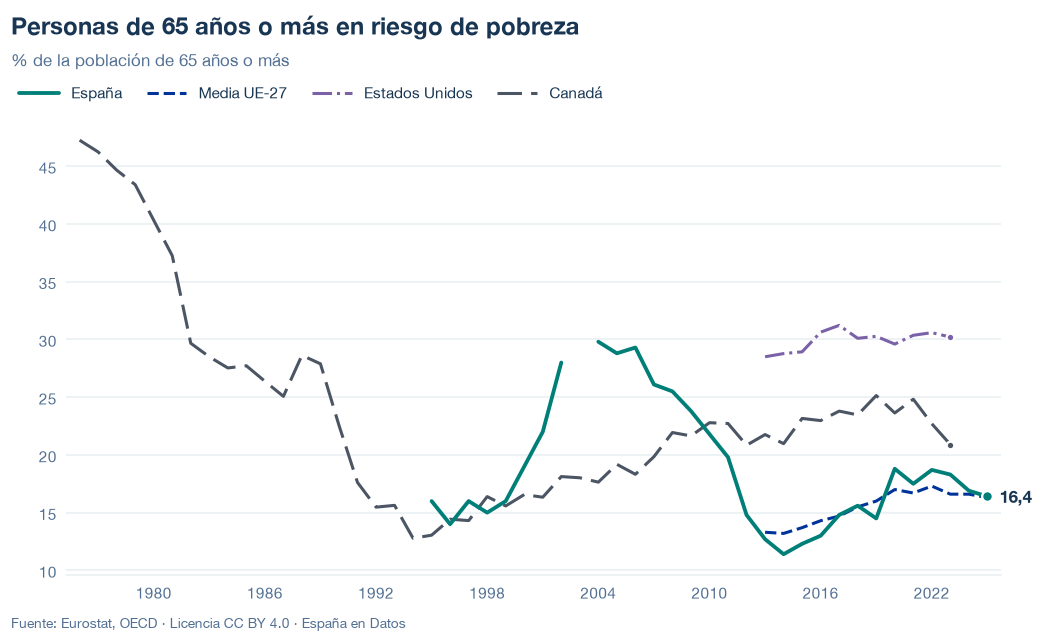

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/riesgo-pobreza-mayores.json y data/riesgo-pobreza-mayores.csv


## 6. Fuentes, notas y licencia

- Eurostat, `ilc_li02` (`Y_GE65`, `T`, `B_60`, `MED_EI`, `PC`): España y UE-27.
- OCDE, IDD (`OECD.WISE.INE,DSD_WISE_IDD@DF_IDD,1.0`, `PR_INC_DISP`, `Y_GT65`, `METH2012`, `D_CUR`, `PL_60`): EE. UU., Canadá y, para comparar, España.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.